# 08-04 - Traffic on a Sensor Graph

You turn 207 traffic sensors of Los Angeles into a graph, forecast their speeds with simple regressions, and measure what the neighbours add.

First the sensors, one week and the graph a rule draws from road distances. Then the task split in time, the gaps, and two baselines. Then a regression on the own hour, with the neighbours, with the clock, and on a graph from straight lines. Last the published deep models, and you change the horizon.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import graph_tools as gt

plt.rcParams["figure.dpi"] = 72

scene = gt.load_json("data/scene.json")
reference = gt.load_json("data/ground_truth.json")["p08"]
rules, anchors, lecture = scene["rules"], scene["anchors"], scene["lecture"]
torch_ok, pyg_ok = gt.torch_ok, gt.pyg_available()
streets, metr = lecture["streets"], lecture["metr"]
print(f"seed {scene['seed']}; {streets['n']:,} street segments, {streets['tagged']} with a speed limit")
print(f"{metr['sensors']} traffic sensors; PyTorch {'ready' if torch_ok else 'missing'}, "
      f"PyTorch Geometric {'ready' if pyg_ok else 'missing'}")

seed 20261116; 1,219 street segments, 454 with a speed limit
207 traffic sensors; PyTorch ready, PyTorch Geometric ready


## Two hundred and seven sensors

The cell loads the speeds and the sensors' places, counts the readings and the missing ones, and maps every sensor by its mean speed.

207 sensors, 34,272 times every 5 minutes from 2012-03-01 00:00 to 2012-06-27 23:55
missing readings 8.1%   lecture 8.1%
at 6.3% of the times every sensor is silent, which holds 77% of the missing readings


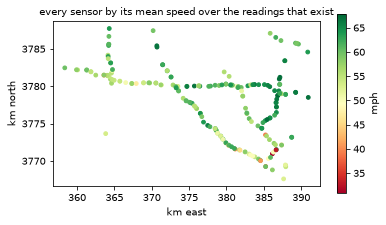

In [2]:
metr = lecture["metr"]
speeds, graph = gt.load_arrays("data/metr_speeds.npz"), gt.load_arrays("data/metr_graph.npz")
X, seconds, ids = speeds["speeds"].astype(float), speeds["seconds"], graph["sensors"]
stamp = [np.datetime_as_string(t, unit="m").replace("T", " ") for t in seconds.astype("datetime64[s]")]
xy = np.c_[graph["x"], graph["y"]]
silent = (X == 0).all(axis=1)
print(f"{X.shape[1]} sensors, {X.shape[0]:,} times every 5 minutes from {stamp[0]} to {stamp[-1]}")
print(f"missing readings {(X == 0).mean():.1%}   lecture {metr['missing_share']:.1%}")
print(f"at {silent.mean():.1%} of the times every sensor is silent, which holds "
      f"{silent.sum() * X.shape[1] / (X == 0).sum():.0%} of the missing readings")
mean_speed = np.array([X[X[:, i] > 0, i].mean() for i in range(X.shape[1])])
ax = gt.show_sensors(xy, mean_speed, title="every sensor by its mean speed over the readings that exist")

Every dot is a loop detector, a coil of wire in the pavement of a freeway, and the dots trace the freeways of Los Angeles County. Red dots are slow on average, green ones fast. A reading of zero means that no reading arrived, and 8.1 percent are missing. Most of them are not single sensors failing. At 6.3 percent of the times the whole system is silent at once, and those moments hold 77 percent of the gaps.

## One sensor's week

The cell draws one week of the sensor the lecture follows, gaps left blank, and its average weekday by five minute step over all weeks.

sensor 773869: 115 of 2016 readings missing in the week from 2012-03-19 00:00
slowest weekday step 17:50, 23 mph, fastest 67 mph


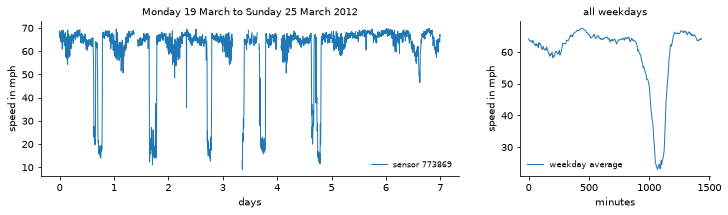

In [3]:
s, start = anchors["sensor"], stamp.index("2012-03-19 00:00")
week = start + np.arange(7 * 288)
step, weekday = (seconds % 86400) // 300, (seconds // 86400 + 3) % 7 < 5
day = np.array([X[(step == k) & weekday & (X[:, s] > 0), s].mean() for k in range(288)])
print(f"sensor {ids[s]}: {(X[week, s] == 0).sum()} of {len(week)} readings missing in the week from "
      f"{stamp[start]}")
hour, minute = divmod(5 * int(day.argmin()), 60)
print(f"slowest weekday step {hour}:{minute:02d}, {day.min():.0f} mph, fastest {day.max():.0f} mph")
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8), gridspec_kw={"width_ratios": [2.2, 1]})
gt.show_series({f"sensor {ids[s]}": X[week, s]}, ax=axes[0], title="Monday 19 March to Sunday 25 March 2012")
ax = gt.show_series({"weekday average": day}, minutes=np.arange(288) * 5, ax=axes[1], title="all weekdays")

On the left a week of five minute speeds with Monday at zero. Look for the blank stretches, the missing readings, and for the deep dip on each weekday evening while the weekend stays near free flow. The right panel averages every weekday of the four months by time of day, in minutes after midnight. The dip there is the daily jam, its slowest step in the evening, and it comes back at nearly the same time every weekday. Keep that regularity in mind for section 11.

## From road distances to a graph

The cell turns the road distance between every two sensors into a weight with the lecture's kernel, cuts the small weights, and counts and draws what remains.

sigma 2,584 m, weights from 0.1 kept, so roads up to 3,922 m   lecture 2,584 m and 3,922 m
1,515 directed edges, 1,313 pairs   lecture 1,515, 1,313; 12.7 neighbours on average, alone 717804


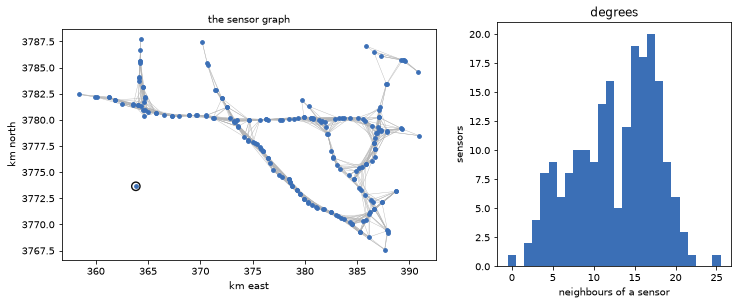

In [4]:
dist = graph["road_dist"].astype(float)
W = gt.kernel_adjacency(dist, rules["metr"]["threshold"])
sigma, off, Wsym = dist[np.isfinite(dist)].std(), ~np.eye(len(W), dtype=bool), gt.symmetric(W)
degree, pairs = ((Wsym > 0) & off).sum(axis=1), np.argwhere(np.triu(Wsym > 0, 1))
print(f"sigma {sigma:,.0f} m, weights from {rules['metr']['threshold']} kept, so roads up to "
      f"{sigma * np.sqrt(np.log(10)):,.0f} m   lecture {metr['sigma_m']:,.0f} m and {metr['kappa_m']:,.0f} m")
print(f"{((W > 0) & off).sum():,} directed edges, {len(pairs):,} pairs   lecture {metr['edges_directed']:,}, "
      f"{metr['edges_undirected']:,}; {degree.mean():.1f} neighbours on average, alone {ids[degree == 0][0]}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
axes[1].hist(degree, bins=np.arange(0, degree.max() + 2) - 0.5, color="#3b6fb6")
axes[1].set(xlabel="neighbours of a sensor", ylabel="sensors", title="degrees")
ax = gt.show_sensors(xy, edges=pairs, mark=np.nonzero(degree == 0)[0], ax=axes[0], title="the sensor graph")

Nobody measured these edges. The weight of a pair is exp of minus the squared road distance over sigma squared, where sigma, 2,584 m, is the spread of all distances, and weights under 0.1 are dropped, which is the same as dropping roads longer than 3,922 m. What remains are 1,515 directed edges, or 1,313 pairs read in both directions. The grey lines follow the freeways. The circled sensor has no neighbour within the cut, and the histogram shows how unequal the neighbourhoods are.

## Road distance against the straight line

The cell compares the two distances for every pair of sensors with a road distance and prints the pair the lecture picked.

sensors 773996 and 773995: 31 m in a straight line, by road 6.6 km there and 6.7 km back; weight 0.00
11,546 ordered pairs carry a road distance; in the median the road is 1.59 times the straight line


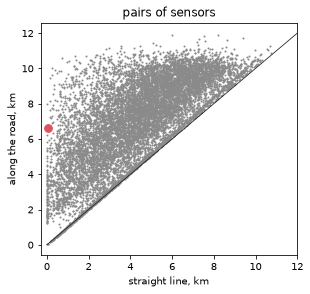

In [5]:
(a, b), line = anchors["line_pair"], graph["line_dist"].astype(float)
print(f"sensors {ids[a]} and {ids[b]}: {line[a, b]:.0f} m in a straight line, by road "
      f"{dist[a, b] / 1000:.1f} km there and {dist[b, a] / 1000:.1f} km back; weight {Wsym[a, b]:.2f}")
known = np.isfinite(dist) & off
print(f"{known.sum():,} ordered pairs carry a road distance; in the median the road is "
      f"{np.median(dist[known] / line[known]):.2f} times the straight line")
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.scatter(line[known] / 1000, dist[known] / 1000, s=1, color="#8a8a8a")
ax.scatter(line[a, b] / 1000, dist[a, b] / 1000, s=60, color="#DB5461")
ax.plot([0, 12], [0, 12], color="#222222", lw=0.8)
ax.set(xlabel="straight line, km", ylabel="along the road, km", xlim=(-0.3, 12), title="pairs of sensors")
plt.show()

Every grey dot is an ordered pair of sensors, its straight-line distance across and its road distance up, and hardly any dot lies below the black line where the two are equal. The red dot sits at the far left and high up. Its two sensors stand 31 m apart, yet a car needs 6.6 km to drive from one to the other. They are most likely the two directions of one highway. The road graph gives them no edge at all.

## The forecasting task split in time

The cell cuts the four months into a training, a validation and a test part in time and lists the forecast origins of each part.

training   2012-03-01 00:00 to 2012-05-23 07:05, 23,990 times, 23,967 origins
validation 2012-05-23 07:10 to 2012-06-04 04:40, 3,427 times, 3,404 origins
test       2012-06-04 04:45 to 2012-06-27 23:55, 6,855 times, 6,832 origins
lecture: test from 2012-06-04 04:45, 6,832 test origins


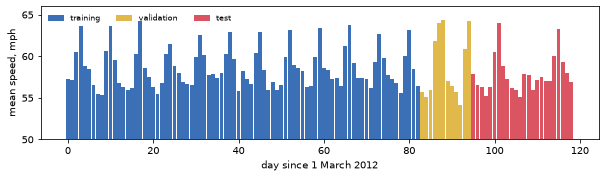

In [6]:
m = rules["metr"]
times, origins = gt.forecast_origins(len(X), m["lags"], max(m["horizons"].values()), m["train"], m["val"])
for name, part, o in zip(("training", "validation", "test"), times, origins):
    print(f"{name:10s} {stamp[part[0]]} to {stamp[part[-1]]}, {len(part):,} times, {len(o):,} origins")
print(f"lecture: test from {metr['split']['test'][0][:16]}, {metr['split']['origins_test']:,} test origins")
daily = np.nanmean(np.where(X > 0, X, np.nan).reshape(-1, 288 * X.shape[1]), axis=1)
fig, ax = plt.subplots(figsize=(10, 2.4))
for name, part, colour in zip(("training", "validation", "test"), times, ("#3b6fb6", "#E0B94A", "#DB5461")):
    ax.bar(np.unique(part // 288), daily[np.unique(part // 288)], color=colour, label=name, width=0.9)
ax.set(xlabel="day since 1 March 2012", ylabel="mean speed, mph", ylim=(50, 66))
ax.legend(frameon=False, fontsize=8, ncol=3)
plt.show()

A forecast origin is a moment at which a forecast is made from the last hour, twelve readings, for 15, 30 and 60 minutes ahead, and every origin keeps its hour behind and its hour ahead inside its own part. The bars are the mean speed of each day, and the weekends stand out as the tall bars. The parts follow each other in time. A random split would put readings five minutes apart into training and test, and the test would score that leak instead of a forecast.

## What a forecaster knows

The cell fills every missing reading with the last reading the sensor sent, and before its first one with its training mean, and shows one gap before and after.

sensor 773869 is silent from 2012-03-05 13:30 to 2012-03-05 14:50, 17 readings
the filled series holds 65.3 mph through the gap, the reading before it


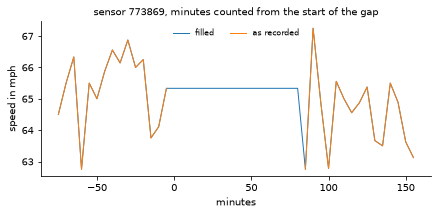

In [7]:
train_mean = np.array([X[times[0]][X[times[0], i] > 0, i].mean() for i in range(X.shape[1])])
Xf = gt.fill_missing(X, start=train_mean)
run = np.convolve((X[:, s] == 0).astype(int), np.ones(12, dtype=int), "valid")
g = int(np.argmax(run == 12))
end = g + int(np.argmax(X[g:, s] > 0))
print(f"sensor {ids[s]} is silent from {stamp[g]} to {stamp[end - 1]}, {end - g} readings")
print(f"the filled series holds {Xf[g - 1, s]:.1f} mph through the gap, the reading before it")
window = np.arange(g - 15, end + 15)
ax = gt.show_series({"filled": Xf[window, s], "as recorded": X[window, s]}, minutes=(window - g) * 5,
                    title=f"sensor {ids[s]}, minutes counted from the start of the gap")

The orange line breaks where nothing arrived, and the blue line is what a forecaster holds at every moment, the last reading it has seen, carried flat through the gap. Missing readings are filled only in the inputs. In every fit and every error below a missing reading is left out, so no model is scored against a value it made up. The training mean only covers the readings before a sensor's first one.

## Baseline one, the last value

The cell forecasts every test reading by the last reading seen and prints the mean absolute error in mph at every step of five minutes up to an hour.

15 minutes ahead: last value 3.50 mph   lecture 3.50
30 minutes ahead: last value 4.21 mph   lecture 4.21
60 minutes ahead: last value 5.38 mph   lecture 5.38


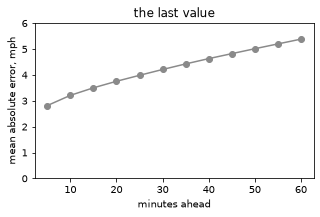

In [8]:
te, H, ref = origins[2], m["horizons"], metr["results"]
for mins, h in H.items():
    print(f"{mins} minutes ahead: last value {gt.masked_mae(Xf[te], X[te + h]):.2f} mph   "
          f"lecture {ref['last'][mins]['mae']:.2f}")
steps = np.arange(1, 13)
curve = [gt.masked_mae(Xf[te], X[te + h]) for h in steps]
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.plot(steps * 5, curve, "o-", color="#8a8a8a")
ax.set(xlabel="minutes ahead", ylabel="mean absolute error, mph", ylim=(0, 6), title="the last value")
plt.show()

The mean absolute error is the average distance in mph between forecast and reading, over the test readings that exist. Repeating the last reading misses by 3.50 mph a quarter of an hour ahead, by 4.21 at half an hour and by 5.38 an hour ahead. The curve rises at every step, because traffic changes little in five minutes and a lot in an hour.

## Baseline two, the historical average

The cell averages every sensor's training readings by five minute slot of the week and forecasts each test reading by the average of its slot.

15 minutes ahead: historical average 4.19 mph   lecture 4.19; last value 3.50
30 minutes ahead: historical average 4.19 mph   lecture 4.19; last value 4.21


60 minutes ahead: historical average 4.19 mph   lecture 4.19; last value 5.38


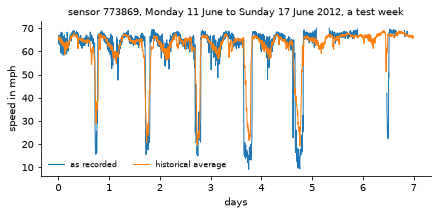

In [9]:
slots = gt.time_of_week(seconds, m["step_s"])
HA = gt.historical_average(X, slots, times[0])
clock = HA[slots]
for mins, h in H.items():
    print(f"{mins} minutes ahead: historical average {gt.masked_mae(clock[te + h], X[te + h]):.2f} mph   "
          f"lecture {ref['ha'][mins]['mae']:.2f}; last value {ref['last'][mins]['mae']:.2f}")
test_week = np.arange(stamp.index("2012-06-11 00:00"), stamp.index("2012-06-11 00:00") + 7 * 288)
series = {"as recorded": X[test_week, s], "historical average": clock[test_week, s]}
ax = gt.show_series(series, title=f"sensor {ids[s]}, Monday 11 June to Sunday 17 June 2012, a test week")

The historical average never looks at the last hour, so its error is 4.19 mph at every horizon. It loses to the last value at 15 and 30 minutes and wins an hour ahead, where the recent past says less than the time of the week. In the picture the orange line is the average of the same slot over the training weeks. It knows when the evening dip comes on a weekday, but not how deep it will be today.

## A regression on the last hour

The cell fits one ridge regression per sensor on its own last twelve readings, an hour ahead, with the lecture's penalty, and shows the weights of one sensor.

own last hour, 60 minutes ahead: 5.29 mph   lecture 5.29; last value 5.38, historical average 4.19
sensor 773869: intercept 33.0 mph, weights summing to 0.47, oldest to latest
[-0.08 -0.01  0.   -0.01 -0.01  0.   -0.02 -0.    0.01  0.02  0.03  0.55]


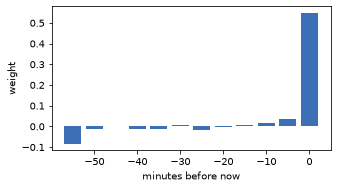

In [10]:
alphas, truth = m["alphas"], X[te + 12]
P_own, _, _ = gt.ridge_forecast(Xf, None, X, origins, 12, False, alphas=[alphas["ar 60"]])
print(f"own last hour, 60 minutes ahead: {gt.masked_mae(P_own, truth):.2f} mph   lecture "
      f"{ref['ar']['60']['mae']:.2f}; last value {ref['last']['60']['mae']:.2f}, historical average "
      f"{ref['ha']['60']['mae']:.2f}")
F, y = gt.forecast_inputs(Xf, None, origins[0], s, h=12), X[origins[0] + 12, s]
w, b = gt.ridge_fit(F[y > 0], y[y > 0], alphas["ar 60"])
print(f"sensor {ids[s]}: intercept {b:.1f} mph, weights summing to {w.sum():.2f}, oldest to latest")
print(np.round(w, 2))
fig, ax = plt.subplots(figsize=(5, 2.6), subplot_kw={"xlabel": "minutes before now", "ylabel": "weight"})
ax.bar(np.arange(-55, 1, 5), w, width=4, color="#3b6fb6")
plt.show()

Ridge regression is a linear model, a weighted sum of the inputs plus an intercept, with a penalty that keeps the weights small. Each sensor gets its own twelve weights for each horizon, fitted on the training weeks. An hour ahead it scores 5.29 mph, a little better than the last value and still well behind the historical average. Look at the bars. The latest readings carry most of the weight, and the weights add up to well below one, so the forecast leans towards the sensor's usual speed.

## With the neighbours' readings

The cell adds the weighted mean of every sensor's neighbours over the same hour as twelve more inputs, refits, and maps how much each sensor gains.

with the neighbours, 60 minutes ahead: 5.18 mph   lecture 5.18; own hour 5.29
better at 156 of 207 sensors   lecture 156; median gain 0.06 mph, largest 1.56, worst -0.64


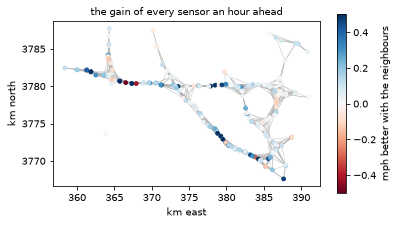

In [11]:
NB = gt.neighbour_average(Xf, Wsym)
P_nb, _, _ = gt.ridge_forecast(Xf, NB, X, origins, 12, True, alphas=[alphas["arnb 60"]])
own, nb = gt.sensor_mae(P_own, truth), gt.sensor_mae(P_nb, truth)
print(f"with the neighbours, 60 minutes ahead: {gt.masked_mae(P_nb, truth):.2f} mph   "
      f"lecture {ref['arnb']['60']['mae']:.2f}; own hour {ref['ar']['60']['mae']:.2f}")
print(f"better at {(nb < own).sum()} of {len(own)} sensors   lecture {metr['helped']['60']}; median gain "
      f"{np.median(own - nb):.2f} mph, largest {(own - nb).max():.2f}, worst {(own - nb).min():.2f}")
ax = gt.show_sensors(xy, own - nb, edges=pairs, cmap="RdBu", label="mph better with the neighbours",
                     title="the gain of every sensor an hour ahead")
ax.collections[0].set_clim(-0.5, 0.5)

The neighbours' mean is message passing from Chapter 3, one round over the sensor graph with the weights scaled to sum to one. With it the error an hour ahead falls from 5.29 to 5.18 mph. Blue dots gained, red ones lost, white ones barely moved, and the colours stop at half a mph either way. The neighbours help 156 of the 207 sensors, mostly by a little, and a few lose where their neighbours behave differently. A real gain, and a small one.

## With the clock

The cell gives the regression the historical average of the target time as one more input, once without and once with the neighbours.

with the clock        60 minutes: 4.03 mph   lecture 4.03
clock and neighbours  60 minutes: 4.03 mph   lecture 4.03
the neighbours' median gain per sensor: 0.058 mph without the clock, -0.002 with it


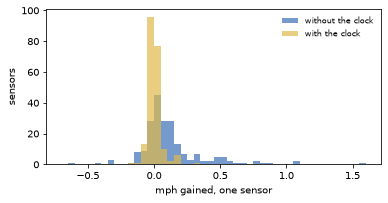

In [12]:
P_clock, _, _ = gt.ridge_forecast(Xf, None, X, origins, 12, False, alphas=[alphas["arclock 60"]], clock=clock)
P_both, _, _ = gt.ridge_forecast(Xf, NB, X, origins, 12, True, alphas=[alphas["arboth 60"]], clock=clock)
for name, P, key in (("with the clock", P_clock, "arclock"), ("clock and neighbours", P_both, "arboth")):
    print(f"{name:21s} 60 minutes: {gt.masked_mae(P, truth):.2f} mph   lecture {ref[key]['60']['mae']:.2f}")
gain_clock = gt.sensor_mae(P_clock, truth) - gt.sensor_mae(P_both, truth)
print(f"the neighbours' median gain per sensor: {np.median(own - nb):.3f} mph without the clock, "
      f"{np.median(gain_clock):.3f} with it")
fig, ax = plt.subplots(figsize=(6, 2.8), subplot_kw={"xlabel": "mph gained, one sensor", "ylabel": "sensors"})
for gain, colour, name in ((own - nb, "#3b6fb6", "without"), (gain_clock, "#E0B94A", "with")):
    ax.hist(gain, bins=np.linspace(-0.7, 1.6, 47), color=colour, alpha=0.7, label=f"{name} the clock")
ax.legend(frameon=False, fontsize=8)
plt.show()

One extra number, the usual speed of this sensor at the target time, drops the error an hour ahead from 5.29 to 4.03 mph, far more than the neighbours gave. With the clock in the model the neighbours add nothing at the printed digit, 4.03 again. The yellow bars crowd at zero. Most of what the neighbours knew an hour ahead was the time of day, which their slowing announced and the clock states outright.

## A graph from straight lines

The cell takes the lecture's graph from straight-line distances, which joins as many pairs as the road graph, compares the pairs, and refits the model with neighbours on it.

1,313 pairs, 931 in both graphs (71%)


with the straight-line neighbours: 5.21 mph   lecture 5.21; road graph 5.18
the road graph is better at 121 of 207 sensors


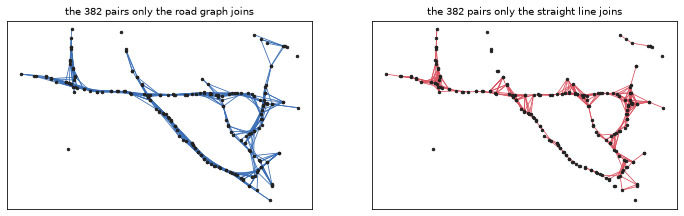

In [13]:
road_pairs, line_pairs = np.triu(Wsym > 0, 1), np.triu(graph["line_W"] > 0, 1)
shared, road_only, line_only = road_pairs & line_pairs, road_pairs & ~line_pairs, line_pairs & ~road_pairs
print(f"{line_pairs.sum():,} pairs, {shared.sum():,} in both graphs ({shared.sum() / line_pairs.sum():.0%})")
NB_line = gt.neighbour_average(Xf, graph["line_W"].astype(float))
P_line, _, _ = gt.ridge_forecast(Xf, NB_line, X, origins, 12, True, alphas=[m["line_alphas"]["arnb 60"]])
print(f"with the straight-line neighbours: {gt.masked_mae(P_line, truth):.2f} mph   lecture "
      f"{metr['line']['results']['arnb']['60']['mae']:.2f}; road graph {gt.masked_mae(P_nb, truth):.2f}")
print(f"the road graph is better at {(nb < gt.sensor_mae(P_line, truth)).sum()} of {len(nb)} sensors")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, only, name in zip(axes, (road_only, line_only), ("road graph", "straight line")):
    gt.show_edges(xy, only, ax=ax, colour="#3b6fb6" if name == "road graph" else "#DB5461",
                  title=f"the {only.sum()} pairs only the {name} joins")

The two graphs share 71 percent of their pairs, and each joins 382 pairs the other leaves apart. On the left the road graph reaches further along the freeways, and on the right the straight line crowds its pairs around the interchanges, where roads cross without joining. An hour ahead the straight-line graph gives 5.21 mph against the road graph's 5.18, and the road graph wins at the majority of the sensors. The road distance is the better rule, by a small margin.

## The published deep models beside ours

The cell sets the kit's five forecasts an hour ahead beside three rows of Table 1 of Li et al. (2018), trained on the same data with the same split.

HA       15, 30, 60 minutes: 4.16, 4.16, 4.16 mph
FC-LSTM  15, 30, 60 minutes: 3.44, 3.77, 4.37 mph
DCRNN    15, 30, 60 minutes: 2.77, 3.15, 3.60 mph


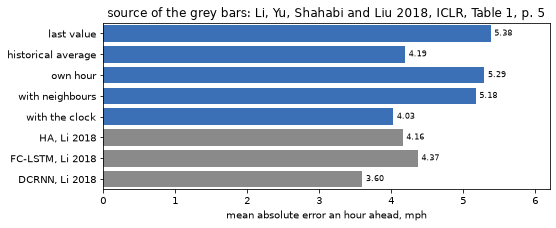

In [14]:
li, ours = metr["li2018"], {"last value": Xf[te], "historical average": clock[te + 12], "own hour": P_own,
              "with neighbours": P_nb, "with the clock": P_clock}
bars = {name: gt.masked_mae(P, truth) for name, P in ours.items()}
for k in ("HA", "FC-LSTM", "DCRNN"):
    bars[f"{k}, Li 2018"] = li[k]["60"][0]
    print(f"{k:8s} 15, 30, 60 minutes: {li[k]['15'][0]:.2f}, {li[k]['30'][0]:.2f}, {li[k]['60'][0]:.2f} mph")
fig, ax = plt.subplots(figsize=(8, 3))
ax.set(xlabel="mean absolute error an hour ahead, mph", xlim=(0, 6.2), ylim=(len(bars) - 0.5, -0.5),
       title=f"source of the grey bars: {li['source']}")
ax.barh(list(bars), list(bars.values()), color=["#3b6fb6"] * 5 + ["#8a8a8a"] * 3)
for k, v in bars.items():
    ax.text(v + 0.05, k, f"{v:.2f}", va="center", fontsize=8)

Blue bars are the kit's, computed here, and grey ones are copied from the paper. The paper's historical average of 4.16 lies next to ours at 4.19, a check that the split matches. DCRNN, a recurrent network whose cells pass messages over the directed sensor graph, reaches 3.60 mph an hour ahead, against 4.03 for our model with the clock. FC-LSTM, a deep network without the graph, reaches 4.37. The kit trains no deep model, and those three numbers are the authors'.

## Your turn

Every regression above forecast an hour ahead. Fit the regression on the sensor's own hour and the one with the neighbours at another horizon. The cell looks up the lecture's penalties for that horizon and fits both models. Run the cell as it is, then change the marked value and run it again.

How large is the neighbours' gain at the new horizon, and why do the neighbours matter less for a short forecast than for an hour ahead? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

In [15]:
HORIZON = 60  # change me: 15
h = HORIZON // 5
P_a, _, _ = gt.ridge_forecast(Xf, None, X, origins, h, False, alphas=[alphas[f"ar {HORIZON}"]])
P_b, _, _ = gt.ridge_forecast(Xf, NB, X, origins, h, True, alphas=[alphas[f"arnb {HORIZON}"]])
e_a, e_b = gt.masked_mae(P_a, X[te + h]), gt.masked_mae(P_b, X[te + h])
helped = (gt.sensor_mae(P_b, X[te + h]) < gt.sensor_mae(P_a, X[te + h])).sum()
print(f"{HORIZON} minutes ahead: own hour {e_a:.2f} mph, with the neighbours {e_b:.2f} mph")
print(f"the neighbours' gain {e_a - e_b:.2f} mph, better at {helped} of {X.shape[1]} sensors")

60 minutes ahead: own hour 5.29 mph, with the neighbours 5.18 mph
the neighbours' gain 0.12 mph, better at 156 of 207 sensors


## Check your understanding

1. Nobody measured the edges of the sensor graph. Which two choices made them, and what would a larger sigma do to the number of neighbours?
2. Two sensors 31 m apart got no edge. Why is that right for forecasting traffic, and what would a graph from straight lines get wrong there?
3. Why must the split be in time, and what would a random split of the five minute readings score instead of a forecast?
4. With the clock in the model the neighbours added nothing at 60 minutes. What did the neighbours' readings carry that the clock already knew?

## Where we are

You have built a graph from road distances, forecast traffic with baselines split in time, and measured the neighbours' gain with and without the clock. Across the four notebooks a graph helped where its edges carried something the features lacked, the streets more than distance, and helped little where the features or the clock already knew it. That is why every project that uses a graph reports a baseline without one. This is the last notebook of the kit. Next comes your project, where a graph earns its place against a baseline without one, and CEE520 in the spring takes graph learning further.

## Further resources

Nothing in this course requires anything below.

- Diffusion Convolutional Recurrent Neural Network: Data-Driven Traffic Forecasting, Yaguang Li, Rose Yu, Cyrus Shahabi and Yan Liu, ICLR 2018, https://arxiv.org/abs/1707.01926, Table 1 on page 5
- Spatio-Temporal Graph Convolutional Networks: A Deep Learning Framework for Traffic Forecasting, Bing Yu, Haoteng Yin and Zhanxing Zhu, IJCAI 2018, https://doi.org/10.24963/ijcai.2018/505
- ETA Prediction with Graph Neural Networks in Google Maps, Austin Derrow-Pinion and others, CIKM 2021, https://doi.org/10.1145/3459637.3481916
- Graph Deep Learning for Time Series Forecasting, Andrea Cini, Ivan Marisca, Daniele Zambon and Cesare Alippi, arXiv 2023, https://arxiv.org/abs/2310.15978

The tables, numbers and this kit are the course's own work, published under CC BY 4.0. The traffic speeds are the METR-LA dataset of Li, Yu, Shahabi and Liu (2018), loop-detector readings of the Los Angeles County highways collected by Caltrans PeMS. The release states no licence.